# Does the FLT1 module replicate better than modules built around other genes? (Addendum H)

Addendum H was committed before this notebook was run. It repeats the **whole** Addendum F procedure
(selection in GSE114691 → test in GSE203507) for 300 random "anchor" genes matched to FLT1's expression
level, and asks where FLT1 ranks. Run notebooks 01, 05 and 09 first.

In [1]:
import os, sys, warnings
from pathlib import Path
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path(".."); EXT = ROOT / "data_external"
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(EXT / "h.all.v2024.1.Hs.symbols.gmt")}
HYP = set(gmt["HALLMARK_HYPOXIA"]); N_MODULE = 50; N_ANCHORS = 300

def vst_of(counts, groups):
    counts = counts.loc[(counts >= 10).sum(axis=1) >= 5]
    md = pd.DataFrame({"g": groups}, index=counts.columns)
    dds = DeseqDataSet(counts=counts.T.astype(int), metadata=md, design="~g", inference=DefaultInference(n_cpus=4), quiet=True)
    dds.fit_size_factors(); dds.vst(use_design=False)
    return pd.DataFrame(dds.layers["vst_counts"], index=counts.columns, columns=counts.index)
def zs(v): return (v - v.mean()) / v.std()
def hyp_score(vst):
    z = zs(vst); return z[sorted(g for g in HYP if g in z.columns)].mean(axis=1)
def rank_resid(M, covs):
    R = np.column_stack([np.ones(M.shape[0])] + [stats.rankdata(c) for c in covs])
    X = np.apply_along_axis(stats.rankdata, 0, M)
    return X - R @ np.linalg.lstsq(R, X, rcond=None)[0]
def partial_spearman(x, y, covs):
    e = rank_resid(np.column_stack([x, y]), covs); return np.corrcoef(e[:, 0], e[:, 1])[0, 1]

# GSE114691 (selection cohort)
tx2gene = pd.read_csv(EXT / "grch37_tx2gene.tsv", sep="\t").set_index("Transcript stable ID")["Gene name"]
parts = []
for g, f in {"control": "ControlONLY", "IUGR": "IUGRONLY", "PE": "PEONLY", "PE+IUGR": "PEIUGR"}.items():
    d = pd.read_csv(EXT / f"GSE114691_MasterCount_{f}.txt.gz", sep="\t", index_col=0); d.columns = [f"{g}|{c}" for c in d.columns]; parts.append(d)
tx = pd.concat(parts, axis=1); m = tx.index.isin(tx2gene.index)
gc_r = tx[m].groupby(tx2gene.reindex(tx.index[m]).values).sum().round().astype(int)
grp_r = pd.Series([c.split("|")[0] for c in gc_r.columns], index=gc_r.columns)
vst_r = vst_of(gc_r, grp_r.str.startswith("PE").values)
h_r = hyp_score(vst_r)
RES_R = pd.DataFrame(rank_resid(vst_r.values, [h_r.values]), index=vst_r.index, columns=vst_r.columns)
RC = RES_R - RES_R.mean(); norms = np.sqrt((RC ** 2).sum())

# GSE203507 (test cohort)
counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
vst_d = vst_of(counts, meta.pe_status.values); z_d = zs(vst_d); h_d = hyp_score(vst_d)
pre = meta.index[meta.group != "TB"]
dd = meta.loc[pre, ["group", "ga_delivery_weeks", "fetal_sex"]].copy(); dd["hyp"] = h_d[pre]
dd["grp"] = dd.group.map({"iPTB": "ctrl", "EOPE": "EOPE", "EOPE+FGR": "EOPEFGR", "FGR": "FGR"})

def run_anchor(a):
    pc = (RC.mul(RC[a], axis=0).sum()) / (norms * norms[a])
    pc = pc.drop(index=a).dropna()
    cand = pc[~pc.index.isin(HYP)].sort_values(ascending=False)
    module = list(cand.index[:N_MODULE])
    mod_d = [g for g in module if g in z_d.columns]
    ms = z_d.loc[pre, mod_d].mean(axis=1)
    v1 = partial_spearman(ms.values, vst_d.loc[pre, a].values, [dd.hyp.values])
    x = dd.copy(); x["module"] = ms
    f = smf.ols("module ~ C(grp, Treatment('ctrl')) + hyp + ga_delivery_weeks + C(fetal_sex)", data=x).fit()
    nm = {g: f"C(grp, Treatment('ctrl'))[T.{g}]" for g in ["EOPE", "EOPEFGR", "FGR"]}
    v2 = 0.5 * f.params[nm["EOPE"]] + 0.5 * f.params[nm["EOPEFGR"]] - f.params[nm["FGR"]]
    return {"anchor": a, "selection_strength": cand.iloc[N_MODULE - 1], "n_module_in_test": len(mod_d), "V1_partial_rho": v1, "V2_PE_minus_FGR": v2}

## H1. Anchor genes matched to FLT1's expression level

In [2]:
mean_r = vst_r.mean(); dec = pd.qcut(mean_r, 10, labels=False)
eligible = sorted(g for g in vst_r.columns if g not in HYP and g != "FLT1" and g in vst_d.columns and dec[g] == dec["FLT1"])
rng = np.random.default_rng(42)
anchors = list(rng.choice(eligible, N_ANCHORS, replace=False))
print(f"FLT1 expression decile: {dec['FLT1']} | eligible anchors: {len(eligible)} | sampled: {N_ANCHORS}")
flt = run_anchor("FLT1")
null = pd.DataFrame([run_anchor(a) for a in anchors])
null.to_csv(RES_DIR / "H1_anchor_null.csv", index=False)
pct_v1 = (null.V1_partial_rho < flt["V1_partial_rho"]).mean() * 100
pct_v2 = (null.V2_PE_minus_FGR < flt["V2_PE_minus_FGR"]).mean() * 100
h1 = pd.DataFrame([{**flt, "V1_percentile_among_anchors": pct_v1, "V2_percentile_among_anchors": pct_v2,
                    "anchor_V1_median": null.V1_partial_rho.median(), "anchor_V1_95th": null.V1_partial_rho.quantile(.95),
                    "anchor_V2_median": null.V2_PE_minus_FGR.median(), "anchor_V2_95th": null.V2_PE_minus_FGR.quantile(.95)}])
h1.to_csv(RES_DIR / "H1_flt1_vs_anchors.csv", index=False)
pd.set_option("display.width", 220); print(h1.round(3).T.to_string())
verdict = ("FLT1 module replicates unusually well (>= 95th percentile)" if pct_v1 >= 95 else
           "F1 result mainly reflects general co-expression reproducibility; claim limited to 'FLT1 sits in a reproducible co-expression module'")
print("\nPre-specified verdict:", verdict)

FLT1 expression decile: 9 | eligible anchors: 2567 | sampled: 300


                                  0
anchor                         FLT1
selection_strength            0.774
n_module_in_test                 44
V1_partial_rho                0.887
V2_PE_minus_FGR               0.586
V1_percentile_among_anchors  95.667
V2_percentile_among_anchors  76.333
anchor_V1_median              0.629
anchor_V1_95th                0.875
anchor_V2_median                0.3
anchor_V2_95th                0.727

Pre-specified verdict: FLT1 module replicates unusually well (>= 95th percentile)


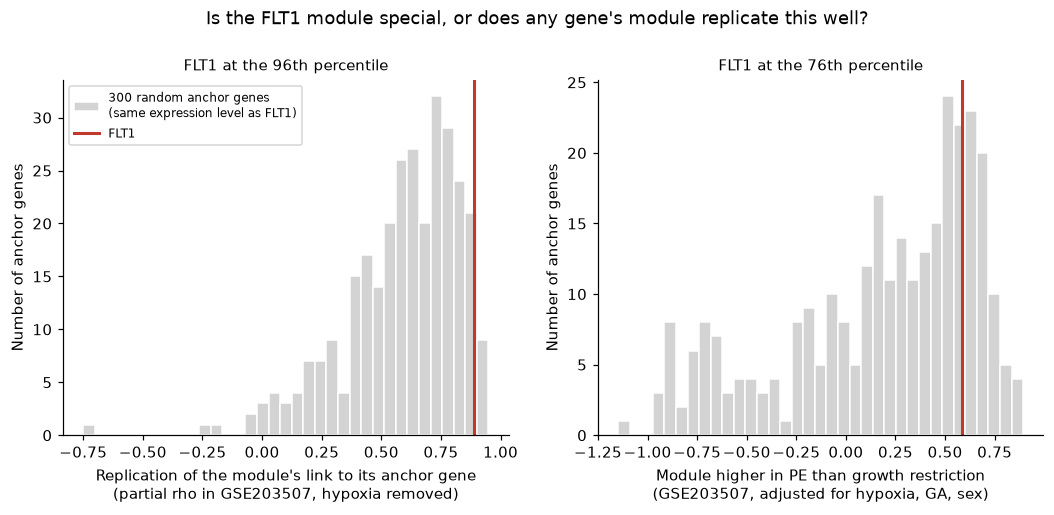

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, col, lab in [(axes[0], "V1_partial_rho", "Replication of the module's link to its anchor gene\n(partial rho in GSE203507, hypoxia removed)"),
                     (axes[1], "V2_PE_minus_FGR", "Module higher in PE than growth restriction\n(GSE203507, adjusted for hypoxia, GA, sex)")]:
    ax.hist(null[col], bins=35, color="lightgrey", edgecolor="white", label=f"{N_ANCHORS} random anchor genes\n(same expression level as FLT1)")
    ax.axvline(flt[col], c="#c0392b", lw=2, label="FLT1")
    ax.set_xlabel(lab); ax.set_ylabel("Number of anchor genes")
axes[0].legend(fontsize=8)
axes[0].set_title(f"FLT1 at the {pct_v1:.0f}th percentile", fontsize=10); axes[1].set_title(f"FLT1 at the {pct_v2:.0f}th percentile", fontsize=10)
fig.suptitle("Is the FLT1 module special, or does any gene's module replicate this well?", y=1.03)
plt.savefig(FIG_DIR / "fig14_anchor_null.png", dpi=300, bbox_inches="tight"); plt.show()